# Drawing the outlines of regions

makes plots nicer ok

Why not just use the original shape files? Firstly, plots can look better when all of the elements are consistent, in this case all using the same grid system. Secondly, sometimes we have access to the grid data and not the underlying shapes. For example, we might define new regions based on a metric such as travel time to the nearest hospital, and not have the memory to keep all of the shapes loaded or have the compute power to use those shapes to quickly make new region shapes.

## Code setup

In [1]:
# Setting up paths to files:
import os
from dataclasses import dataclass

import numpy as np  # for loading grids
import json  # for loading grid dictionary
import matplotlib.pyplot as plt
import shapely.plotting  # to plot outlines

# Add path to package:
import sys
sys.path.insert(0,'../')
import isopods.outline

In [2]:
@dataclass(frozen=True)
class Paths:
    '''Singleton object for storing paths to data and database.'''

    dir_data: str = '../data'
    dict_filename: str = 'lsoa2011_devon_1k_dict.json'
    lsoa_grid_data_filename: str = 'lsoa2011_devon_1k_grid_data.csv'
    lsoa_grid_mask_filename: str = 'lsoa2011_devon_1k_grid_mask.csv'
    district_grid_data_filename: str = 'district2011_devon_1k_grid_data.csv'
    district_grid_mask_filename: str = 'district2011_devon_1k_grid_mask.csv'

paths = Paths()

## Load grid data

Load in the grid dictionary:

In [3]:
p = os.path.join(paths.dir_data, paths.dict_filename)
with open(p, 'r') as f:
    transform_dict = json.load(f)

In [4]:
transform_dict

{'xmin': 212000.0,
 'ymin': 34000.0,
 'xmax': 338000.0,
 'ymax': 152000.0,
 'cell_width': 1000,
 'cell_height': 1000,
 'n_cols': 126,
 'n_rows': 118,
 'im_xmax': 338000.0,
 'im_ymin': 34000.0}

For plotting the grid with imshow:

In [5]:
extent = (transform_dict['xmin'], transform_dict['xmax'],
          transform_dict['ymin'], transform_dict['ymax'])

## LSOA

Load a grid of LSOA from file:

In [6]:
p_d = os.path.join(paths.dir_data, paths.lsoa_grid_data_filename)
p_m = os.path.join(paths.dir_data, paths.lsoa_grid_mask_filename)
lsoa_grid_data = np.loadtxt(p_d, dtype=str, delimiter=',')
lsoa_grid_mask = np.loadtxt(p_m, dtype=bool, delimiter=',')

arr_lsoa = np.ma.MaskedArray(
    lsoa_grid_data, mask=lsoa_grid_mask, dtype=object)

Generate some "random" values for the regions. 

The resulting values are not entirely random because there is some ordering to the list. The `unique()` function sorts the LSOA codes alphanumerically. The LSOA codes have an order to them, where adjacent regions have similar names. It seems that the LSOA are defined in batches, perhaps by district.

Occasionally LSOA regions are redefined, which means the old shapes and codes are removed and new ones generated. In this case, adjacent regions would no longer have similar codes.

In [7]:
# Convert to grid containing this data:
try:
    labels_unique = np.unique(arr_lsoa.compressed())  # masked array
except AttributeError:
    labels_unique = np.unique(arr_lsoa)  # normal array
np.random.seed(42)
dict_labels_to_data = dict(
    # zip(labels_unique, np.random.randint(0, 11, len(labels_unique))))
    zip(labels_unique, np.arange(len(labels_unique))))

Place these random values in the grid:

In [8]:
arr_lsoa_values = isopods.convert.convert_grid_values(
    arr_lsoa, dict_labels_to_data)

## Plot the regions

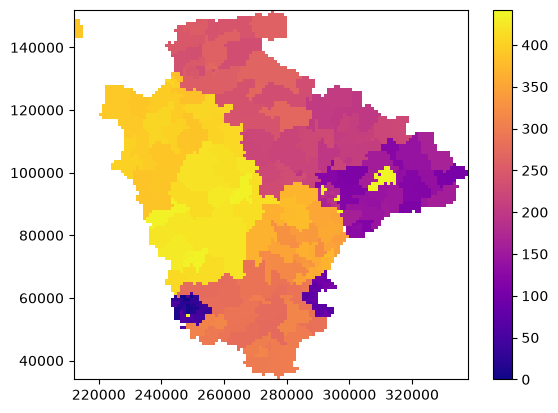

In [9]:
fig, ax = plt.subplots()
# Draw gridded data:
cmap = plt.get_cmap('plasma')
cl = ax.imshow(arr_lsoa_values, origin='lower', extent=extent,
               interpolation='None', cmap=cmap)
plt.colorbar(cl)
plt.show()

It looks like there are a few distinct borders between areas. Are these the edges of districts?

We can draw outlines around the regions and overlay them on the above plot.

## Set up districts

Load a grid of districts from file:

In [10]:
p_d = os.path.join(paths.dir_data, paths.district_grid_data_filename)
p_m = os.path.join(paths.dir_data, paths.district_grid_mask_filename)
district_grid_data = np.loadtxt(p_d, dtype=str, delimiter=',')
district_grid_mask = np.loadtxt(p_m, dtype=bool, delimiter=',')

arr_districts = np.ma.MaskedArray(
    district_grid_data, mask=district_grid_mask, dtype=object)

Make outlines:

In [11]:
dict_polys_pixels = isopods.outline.convert_grid_to_polys(arr_districts)
dict_polys = isopods.outline.transform_poly_dict_coords(
    dict_polys_pixels, transform_dict)

Check the results:

In [12]:
dict_polys_pixels

{'East Devon': <MULTIPOLYGON (((82 68, 82 70, 83 70, 83 68, 82 68)), ((88 45, 88 46, 87 46,...>,
 'Exeter': <POLYGON ((84 53, 84 55, 79 55, 79 57, 78 57, 78 61, 79 61, 79 62, 81 62, 81...>,
 'Mid Devon': <POLYGON ((65 57, 65 58, 64 58, 64 59, 61 59, 61 58, 60 58, 60 59, 59 59, 59...>,
 'North Devon': <POLYGON ((64 76, 64 78, 63 78, 63 79, 61 79, 61 80, 55 80, 55 79, 54 79, 54...>,
 'Plymouth': <MULTIPOLYGON (((34 16, 34 17, 36 17, 36 16, 34 16)), ((39 17, 39 18, 34 18,...>,
 'South Hams': <POLYGON ((65 0, 65 1, 64 1, 64 2, 61 2, 61 1, 60 1, 60 2, 57 2, 57 4, 55 4,...>,
 'Teignbridge': <POLYGON ((62 30, 62 31, 61 31, 61 38, 60 38, 60 37, 59 37, 59 36, 58 36, 58...>,
 'Torbay': <POLYGON ((77 20, 77 22, 76 22, 76 24, 74 24, 74 25, 73 25, 73 28, 75 28, 75...>,
 'Torridge': <MULTIPOLYGON (((22 51, 22 56, 21 56, 21 57, 20 57, 20 59, 21 59, 21 60, 20 ...>,
 'West Devon': <POLYGON ((32 27, 32 28, 31 28, 31 30, 29 30, 29 32, 30 32, 30 35, 31 35, 31...>}

In [13]:
dict_polys

{'East Devon': <MULTIPOLYGON (((294000 102000, 294000 104000, 295000 104000, 295000 102000,...>,
 'Exeter': <POLYGON ((296000 87000, 296000 89000, 291000 89000, 291000 91000, 290000 91...>,
 'Mid Devon': <POLYGON ((277000 91000, 277000 92000, 276000 92000, 276000 93000, 273000 93...>,
 'North Devon': <POLYGON ((276000 110000, 276000 112000, 275000 112000, 275000 113000, 27300...>,
 'Plymouth': <MULTIPOLYGON (((246000 50000, 246000 51000, 248000 51000, 248000 50000, 246...>,
 'South Hams': <POLYGON ((277000 34000, 277000 35000, 276000 35000, 276000 36000, 273000 36...>,
 'Teignbridge': <POLYGON ((274000 64000, 274000 65000, 273000 65000, 273000 72000, 272000 72...>,
 'Torbay': <POLYGON ((289000 54000, 289000 56000, 288000 56000, 288000 58000, 286000 58...>,
 'Torridge': <MULTIPOLYGON (((234000 85000, 234000 90000, 233000 90000, 233000 91000, 232...>,
 'West Devon': <POLYGON ((244000 61000, 244000 62000, 243000 62000, 243000 64000, 241000 64...>}

We have two dictionaries here. The first, `dict_polys_pixels`, is in cell coordinates. The second, `dict_polys`, has scaled the values using the width and height of each cell, with the resulting values being in British National Grid coordinates like the other data.

## Plot district outlines

Use the polygons from the dictionary with the same coordinate system as the main grid.

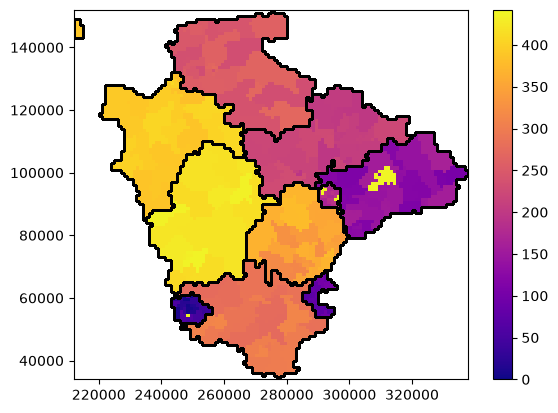

In [14]:
fig, ax = plt.subplots()

# Draw gridded data:
cmap = plt.get_cmap('plasma')
cl = ax.imshow(arr_lsoa_values, origin='lower', extent=extent,
               interpolation='None', cmap=cmap)
plt.colorbar(cl)

# Overlay outlines:
for region, poly in dict_polys.items():
    # Convert polygon to a matplotlib patch:
    # Need antialiased=False to make borders appear to line up with
    # grid. Underlying shapes fine, but antialiased=True makes them
    # look offset in places.
    p = shapely.plotting.patch_from_polygon(
        poly, facecolor=(0, 0, 0, 0), edgecolor='k', antialiased=False
    )
    ax.add_patch(p)

plt.show()

This confirms that the sharp changes in colour in the earlier image line up with the edges of districts.

## Conclusion

Drawing the region outlines can be useful for comparing finer results across regions.